# 08 · Detección de anomalías con PatchCore (Anomalib)

PatchCore **aprende solo de toallas OK**:
1. Extrae características de cada parche de 8×8 px con una red preentrenada (WideResNet-50, capas 2 y 3).
2. Guarda un *coreset* (1 %) de esas características como "memoria de tela normal".
3. En inferencia, un parche lejano a todo lo que hay en la memoria es una **anomalía**.

Ventajas para Galia:
- No necesita anotar defectos y detecta **tipos de defecto nunca vistos**.
- Aprovecha las ~800 fotos OK de abril, que no tienen cajas.

Detalles de implementación:
- Recortes de 512 px de la toalla, reducidos a 256 px.
- Solo se analiza la región de la toalla (máscara por color), para que el fondo y la máquina no generen falsas alarmas.
- El banco de memoria completo (~1.5 M vectores) no cabe en la GPU de 6 GB. Por eso el ajuste usa `PatchcoreModel` de Anomalib en un loop propio: las características se acumulan en RAM y el coreset greedy corre en la GPU sobre la proyección aleatoria.

```bash
python scripts/07_train_patchcore.py --max-tiles 1500 --coreset 0.01
```

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from galia import config as C, viz
from galia.data import load_manifest, load_image, load_boxes
from galia.models import PatchcorePredictor
viz.setup()
WEIGHTS = C.MODELS_DIR / "patchcore_wrn50.pt"
ck = torch.load(WEIGHTS, map_location="cpu", weights_only=False)
print(f"Backbone: {ck['backbone']} {ck['layers']} | recortes OK usados: {ck['n_tiles']} | "
      f"memoria: {ck['memory_bank'].shape[0]:,} × {ck['memory_bank'].shape[1]}")

Backbone: wide_resnet50_2 ['layer2', 'layer3'] | recortes OK usados: 1500 | memoria: 15,360 × 1536


## 1. Ejemplos de recortes "normales" usados para entrenar

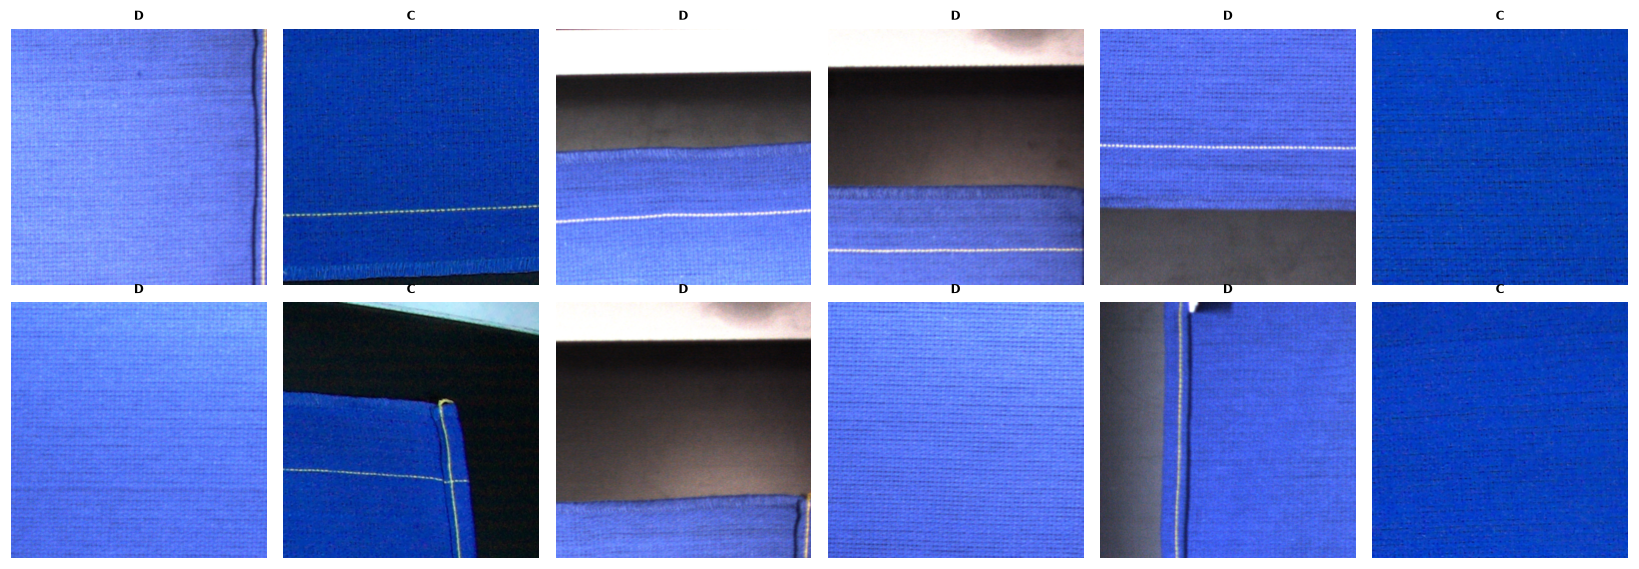

In [2]:
files = sorted((C.PATCHCORE_TILES_DIR / "train" / "good").glob("*.png"))
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))
for ax, f in zip(axes.flat, rng.choice(files, 12, replace=False)):
    ax.imshow(plt.imread(f)); ax.set_axis_off(); ax.set_title(f.name.split("_")[0], fontsize=8)
plt.tight_layout()

## 2. Score de anomalía por toalla (validación)

,,count,mean,50%,max
source,label,,,,
A,NG,34.0,51.50,48.95,77.20
B,NG,39.0,54.88,52.41,78.10
C,OK,38.0,49.23,46.97,62.90
D,OK,119.0,45.56,43.97,66.82


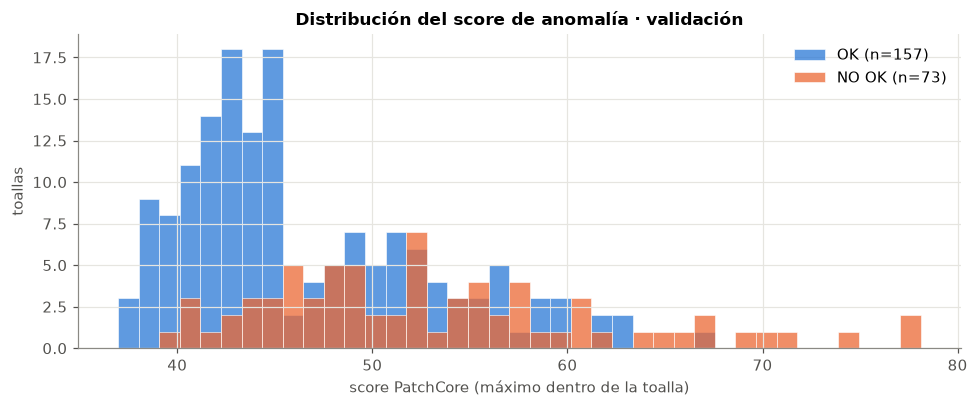

In [3]:
scores = pd.read_csv(C.REPORTS_DIR / "scores_val.csv", keep_default_na=False)
fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.linspace(scores.patchcore.min(), scores.patchcore.max(), 40)
for lab, name in [("OK", "OK"), ("NG", "NO OK")]:
    ax.hist(scores.loc[scores.label == lab, "patchcore"], bins=bins, alpha=0.75, color=viz.LABEL_COLORS[lab],
            label=f"{name} (n={int((scores.label == lab).sum())})", edgecolor="white", linewidth=0.5)
ax.set_xlabel("score PatchCore (máximo dentro de la toalla)"); ax.set_ylabel("toallas"); ax.legend()
ax.set_title("Distribución del score de anomalía · validación")
plt.tight_layout()
scores.groupby(["source", "label"]).patchcore.describe()[["count", "mean", "50%", "max"]].round(2)

## 3. Mapas de anomalía (test)
Recuadros verdes: defectos anotados. Las zonas brillantes son donde PatchCore no reconoce la tela como normal.

C:\Users\Marcony1\miniconda3\envs\galia_v2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\Marcony1\miniconda3\envs\galia_v2\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
C:\Users\Marcony1\miniconda3\envs\galia_v2\Lib\site-packages\anomalib\models\image\dinomaly\components\layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention


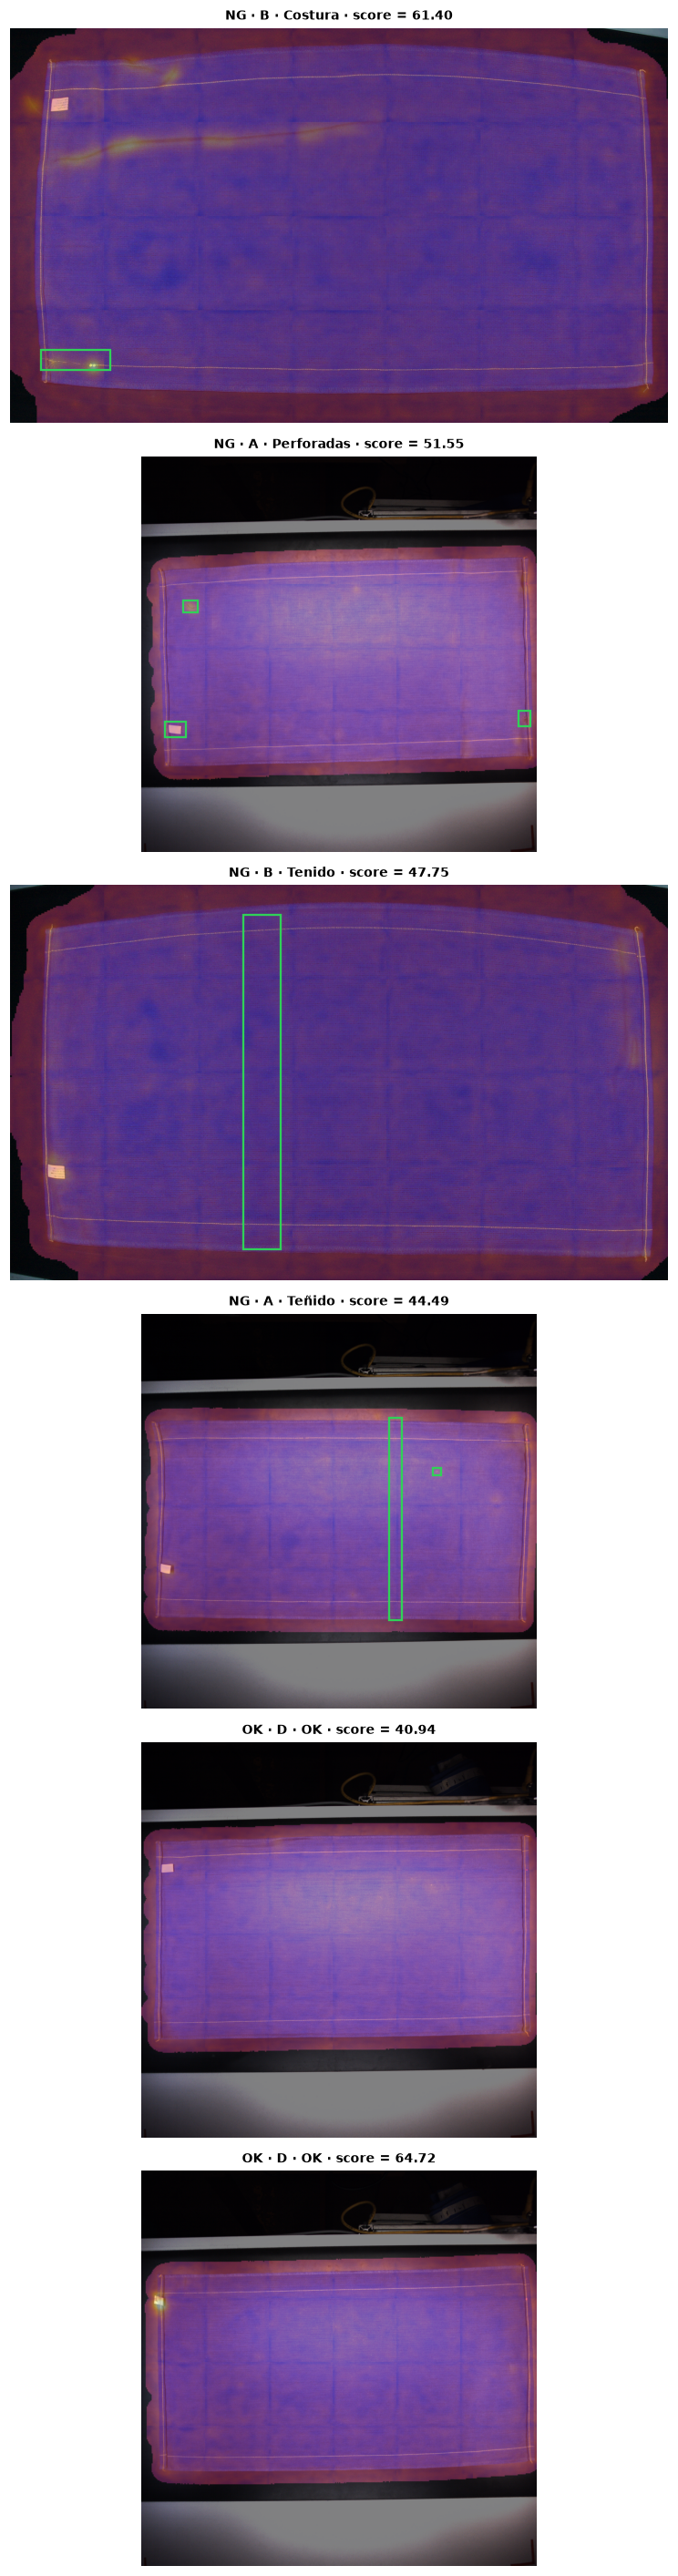

In [4]:
pred = PatchcorePredictor(WEIGHTS)
df = load_manifest(); test = df[df.split == "test"]
ex = pd.concat([test[(test.label == "NG") & (test.n_defect_boxes > 0)].sample(4, random_state=11),
                test[test.label == "OK"].sample(2, random_state=11)])
vmax = float(np.percentile(scores.patchcore, 95))
fig, axes = plt.subplots(len(ex), 1, figsize=(10, 4.3 * len(ex)))
for ax, r in zip(axes, ex.itertuples()):
    img, s = load_image(r.path, r.source)
    out = pred(img)
    viz.overlay_heatmap(ax, img, out.heatmap, vmax=vmax, alpha=0.5,
                        title=f"{r.label} · {r.source} · {r.category} · score = {out.score:.2f}")
    if r.label_path:
        b = load_boxes(r.label_path, r.width, r.height); b[:, 1:] *= s
        for c, x1, y1, x2, y2 in b:
            if int(c) in C.DEFECT_CLASS_IDS:
                ax.add_patch(plt.Rectangle((x1 - 20, y1 - 20), x2 - x1 + 40, y2 - y1 + 40, fill=False, ec="#30d158", lw=1.5))
plt.tight_layout()